# FinAcc Fraud Model Comparison

This notebook trains and compares several fraud-classification models on the local mock transaction dataset. The test split is a small 20-row holdout, so results should be interpreted as a reproducibility/demo comparison rather than a production-quality benchmark.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_sample_weight
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

RANDOM_STATE = 420
TEST_SIZE = 0.20

project_root = next(
    (candidate for candidate in [Path.cwd(), *Path.cwd().parents]
     if (candidate / "Documents").exists()),
    Path.cwd(),
)

dataset_path = project_root / "Documents" / "mock_finacc_transactions.csv"
if not dataset_path.exists():
    candidate = Path(r"C:\Datasets\ieee-fraud-detection\train_transaction.csv")
    if candidate.exists():
        dataset_path = candidate

print(f"Dataset: {dataset_path}")

Dataset: c:\Projects\FinAcc\Documents\mock_finacc_transactions.csv


In [2]:
df = pd.read_csv(dataset_path)

if "isFraud" not in df.columns:
    raise ValueError("The target column 'isFraud' is missing")

metadata_columns = [
    column
    for column in ["isFraud", "TransactionID", "FraudScenario", "CaseNotes"]
    if column in df.columns
]
X = df.drop(columns=metadata_columns)
y = df["isFraud"].astype(int)

print(f"Shape: {df.shape}")
print("Class distribution:")
print(y.value_counts().sort_index())

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training rows: {len(X_train)}; test rows: {len(X_test)}")

Shape: (100, 396)
Class distribution:
isFraud
0    85
1    15
Name: count, dtype: int64
Training rows: 80; test rows: 20


## Preprocessing

Numeric columns are median-imputed and categorical columns are most-frequent-imputed plus ordinal-encoded. Constant columns are removed before model training.

In [3]:
numeric_columns = X.select_dtypes(include=["number"]).columns.tolist()
categorical_columns = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()

numeric_tree_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

categorical_tree_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1,
    )),
])

tree_preprocessor = ColumnTransformer([
    ("numeric", numeric_tree_pipeline, numeric_columns),
    ("categorical", categorical_tree_pipeline, categorical_columns),
], remainder="drop")

numeric_logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1,
    )),
    ("scaler", StandardScaler()),
])

logistic_preprocessor = ColumnTransformer([
    ("numeric", numeric_logistic_pipeline, numeric_columns),
    ("categorical", categorical_logistic_pipeline, categorical_columns),
], remainder="drop")

## Models

The comparison includes logistic regression, random forest, extra-trees, CatBoost, XGBoost, and a small multilayer perceptron (MLP). Categorical columns are ordinal-encoded for a consistent comparison. Class weighting is used to account for fraud imbalance.

In [4]:
train_counts = y_train.value_counts()
scale_pos_weight = train_counts.get(0, 1) / max(train_counts.get(1, 1), 1)

models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", logistic_preprocessor),
        ("variance", VarianceThreshold()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=RANDOM_STATE,
        )),
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", tree_preprocessor),
        ("variance", VarianceThreshold()),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
    "Extra Trees": Pipeline([
        ("preprocessor", tree_preprocessor),
        ("variance", VarianceThreshold()),
        ("classifier", ExtraTreesClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
    "CatBoost": Pipeline([
        ("preprocessor", tree_preprocessor),
        ("variance", VarianceThreshold()),
        ("classifier", CatBoostClassifier(
            iterations=300,
            learning_rate=0.05,
            depth=6,
            scale_pos_weight=scale_pos_weight,
            loss_function="Logloss",
            eval_metric="PRAUC",
            random_seed=RANDOM_STATE,
            verbose=False,
            allow_writing_files=False,
        )),
    ]),
    "XGBoost": Pipeline([
        ("preprocessor", tree_preprocessor),
        ("variance", VarianceThreshold()),
        ("classifier", XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=scale_pos_weight,
            eval_metric="aucpr",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
    "MLP": Pipeline([
        ("preprocessor", logistic_preprocessor),
        ("variance", VarianceThreshold()),
        ("classifier", MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            alpha=0.001,
            learning_rate_init=0.001,
            max_iter=500,
            early_stopping=True,
            n_iter_no_change=20,
            random_state=RANDOM_STATE,
        )),
    ]),
}

print(f"XGBoost scale_pos_weight: {scale_pos_weight:.4f}")

XGBoost scale_pos_weight: 5.6667


In [5]:
results = []
predictions = {}
probabilities = {}

for model_name, model in models.items():
    print(f"Training {model_name}...")
    if model_name == "MLP":
        sample_weight = compute_sample_weight("balanced", y_train)
        model.fit(X_train, y_train, classifier__sample_weight=sample_weight)
    else:
        model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob),
    })

comparison = pd.DataFrame(results).set_index("Model")
comparison.sort_values("PR-AUC", ascending=False).round(4)

Training Logistic Regression...


Training Random Forest...
Training Extra Trees...
Training CatBoost...
Training XGBoost...
Training MLP...


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression,1.00,1.0,1.0000,1.0000,1.0,1.0
Random Forest,1.00,1.0,1.0000,1.0000,1.0,1.0
Extra Trees,1.00,1.0,1.0000,1.0000,1.0,1.0
CatBoost,1.00,1.0,1.0000,1.0000,1.0,1.0
XGBoost,0.95,1.0,0.6667,0.8000,1.0,1.0
MLP,0.85,0.5,1.0000,0.6667,1.0,1.0


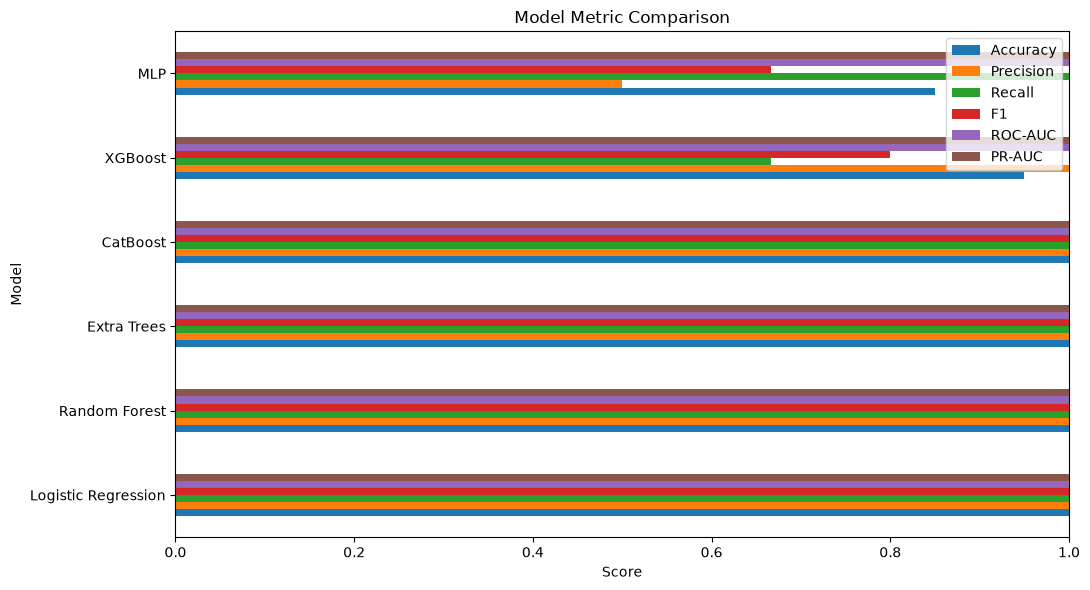

In [6]:
comparison.sort_values("PR-AUC", ascending=True).plot(
    kind="barh",
    y=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"],
    figsize=(11, 6),
)
plt.title("Model Metric Comparison")
plt.xlabel("Score")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

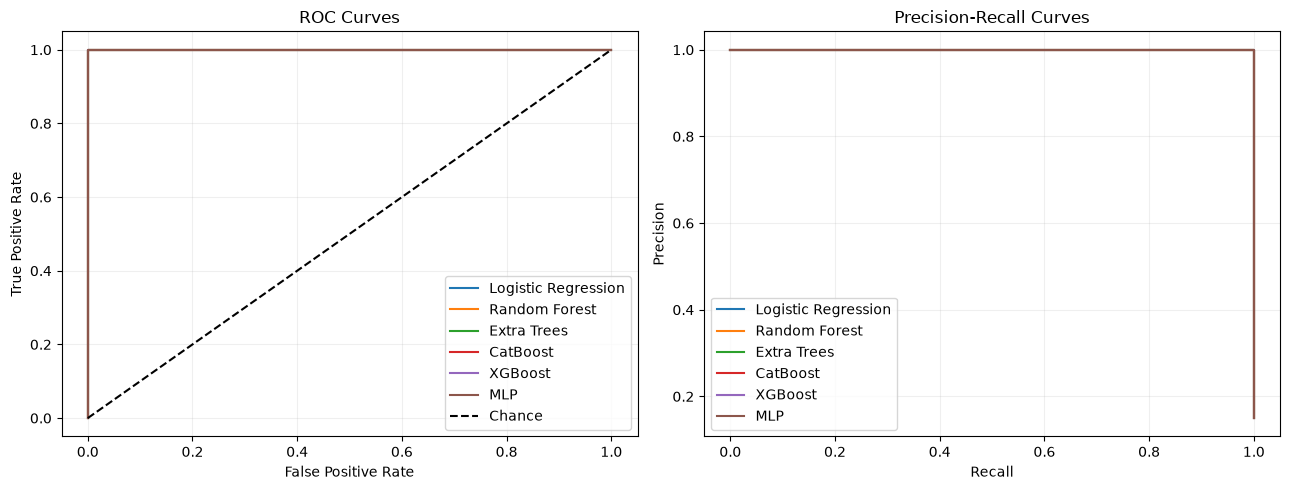

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for model_name, y_prob in probabilities.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, y_prob)
    axes[0].plot(false_positive_rate, true_positive_rate, label=model_name)
axes[0].plot([0, 1], [0, 1], "k--", label="Chance")
axes[0].set_title("ROC Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()
axes[0].grid(alpha=0.2)

for model_name, y_prob in probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    axes[1].plot(recall, precision, label=model_name)
axes[1].set_title("Precision-Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [8]:
for model_name, y_pred in predictions.items():
    print(f"\n--- {model_name} ---")
    print(classification_report(y_test, y_pred, digits=4, zero_division=0))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))


--- Logistic Regression ---
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        17
           1     1.0000    1.0000    1.0000         3

    accuracy                         1.0000        20
   macro avg     1.0000    1.0000    1.0000        20
weighted avg     1.0000    1.0000    1.0000        20

Confusion matrix:
[[17  0]
 [ 0  3]]

--- Random Forest ---
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        17
           1     1.0000    1.0000    1.0000         3

    accuracy                         1.0000        20
   macro avg     1.0000    1.0000    1.0000        20
weighted avg     1.0000    1.0000    1.0000        20

Confusion matrix:
[[17  0]
 [ 0  3]]

--- Extra Trees ---
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        17
           1     1.0000    1.0000    1.0000         3

    accuracy                       